In [1]:
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp  # type: ignore[import]
from pathlib import Path
import matplotlib.pyplot as plt
from functools import partial

# --------------------------------- Internal imports --------------------------------- #
from radiopyo.chemistry.base_chemistry import ReactionRateEnum
from radiopyo.physics.beam import ConstantBeam, ParticleBeam, PulsedBeam
from radiopyo.sim_env import SimEnv
from radiopyo.ode_solver import derive, jac
import radiopyo as rp

In [5]:
from Plot_template import RPlot, FigManager
RPlot.init_rcparams()
fig_man = FigManager(csv=False)

In [2]:
ConstantBeam("e", 100, max_dose=10)

ConstantBeam(particle='e', dose_rate=100, timer=Timer(period=inf, on_time=inf), max_dose=10, time_at_max_dose=0.1, dose_per_pulse=inf, peak_dose_rate=100.0)

In [6]:
file = Path(rf"{rp.__path__[0]}\data\reactions.ron")
beam = PulsedBeam("e",1000, 500e-6, 50e-6, max_dose=2)
beam = ConstantBeam("e", 2, max_dose=5)
env = SimEnv.from_ron_file(file)

t_span = [1e-7, 0.1]


In [7]:
def simulate_large_pulses(env, beam, end_time=1):
    def simul(t_span, y0, **kwargs):
        return solve_ivp(derive, t_span, y0, args=(env, beam), jac=jac, **kwargs)
    
    if beam.timer.duty_cycle() > 0.8:
        raise Exception("Too high duty cycle")
    MAX_STEP_ON = beam.timer.on_time / 100
    MAX_STEP_OFF = (beam.timer.period - beam.timer.on_time) / 10
    kwargs = {}
    kwargs["max_step"] = MAX_STEP_ON
    kwargs["first_step"] = 10e-9
    kwargs["rtol"] = 1e-6
    kwargs["method"] = "LSODA" # Possibilities: ["LSODA", "BDF", "RK45"]

    t_span = [1e-7, beam.timer.on_time*1.1]
    y0 = env.initial_values()
    
    if end_time > beam.time_at_max_dose:
        end_while = beam.time_at_max_dose
    else:
        end_while = end_time
    
    sol = simul(t_span, y0, **kwargs)
    res = sol.y.T
    time = sol.t
    on_time = True
    
    while t_span[1] < end_while:
        if on_time:
            on_time=False
            t_span = [t_span[1], t_span[1]+beam.timer.period-beam.timer.on_time*1.1]
            kwargs["max_step"] = MAX_STEP_OFF
        else:
            on_time=True
            t_span = [t_span[1], t_span[1]+beam.timer.on_time*1.1]
            kwargs["max_step"] = MAX_STEP_ON
            
        sol = simul(t_span, res[-1,:], **kwargs)
        res = np.vstack([res, sol.y.T])
        time = np.append(time, sol.t)
        
    if end_while < end_time:
        kwargs["max_step"] = (end_time-t_span[1]) / 100
        sol = simul([t_span[1], end_time], res[-1,:], **kwargs) 
        res = np.vstack([res, sol.y.T])
        time = np.append(time, sol.t)
    return time, res

In [8]:
beam = ConstantBeam("e", 1e3, max_dose=5)
env = SimEnv.from_ron_file(file)

In [10]:
kwargs = {}
kwargs["max_step"] = np.inf
kwargs["first_step"] = None
kwargs["rtol"] = 1e-8
kwargs["method"] = "LSODA" # Possibilities: ["LSODA", "BDF", "Radau","DOP853","RK45"]
t_span = [1e-9, 0.1]
tlog = np.arange(-9, -2.9, step=0.1)
tspan = np.power(10, tlog)
tspan = np.append(tspan, np.arange(2e-3, 0.1, step=1e-3))
y0 = env.initial_values()
print(y0)
sol = solve_ivp(derive, t_span, y0, args=(env, beam), jac=jac, t_eval=tspan, **kwargs)
time, res = sol.t, sol.y

[ 0.  0.  0.  0.  0. 75.  0.]


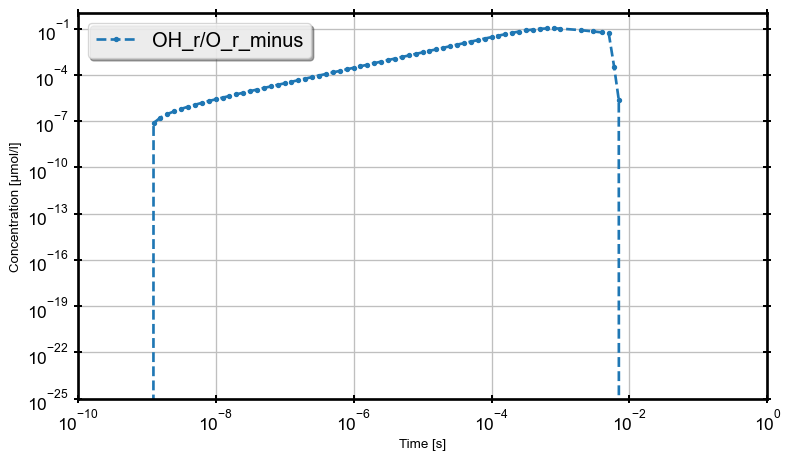

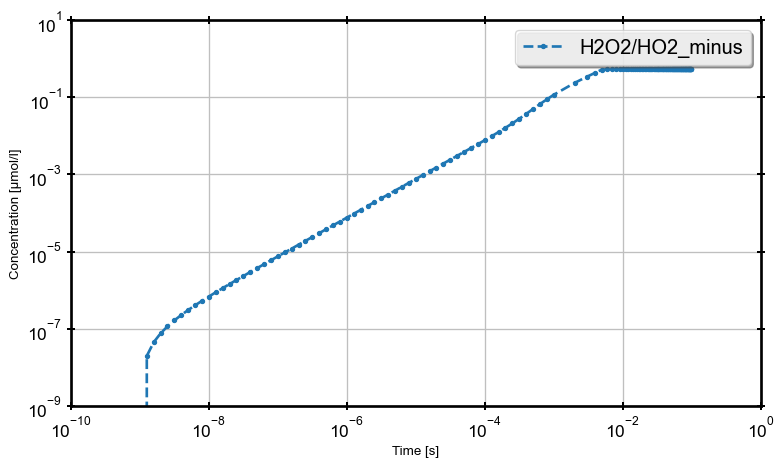

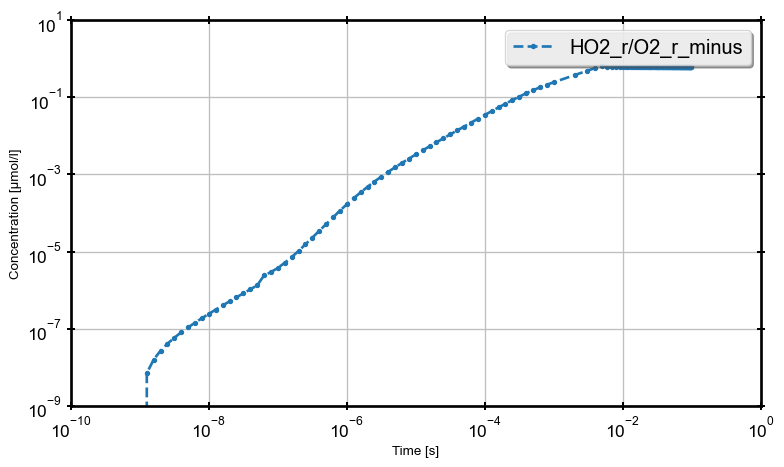

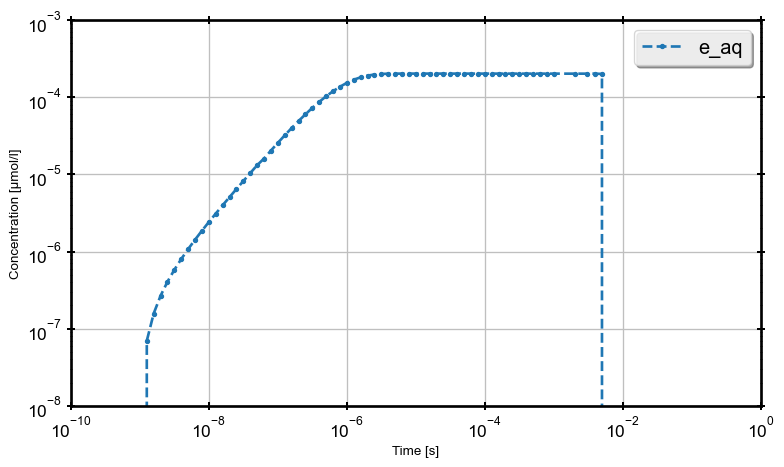

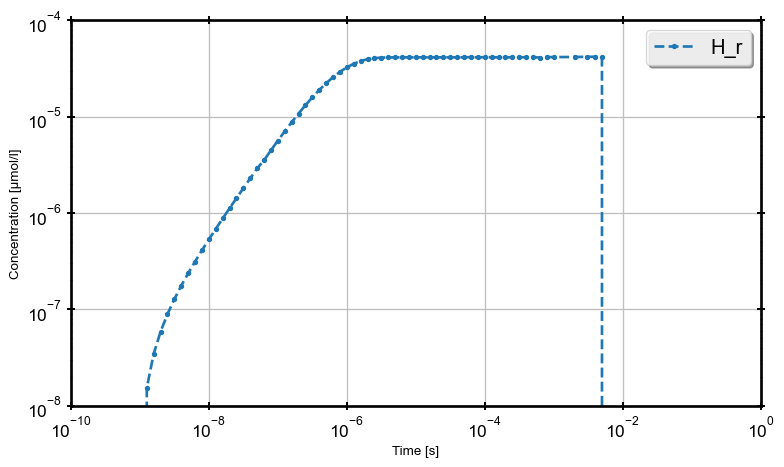

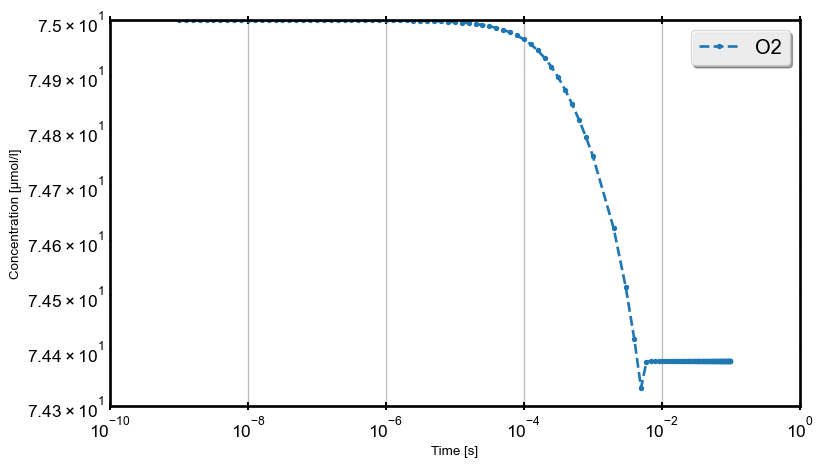

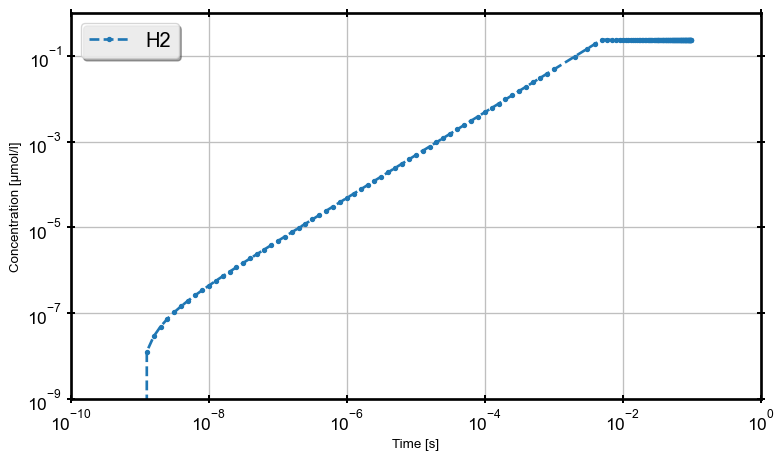

In [48]:
for (label, sp) in zip(env.species_labels(), res):
    with fig_man.open(f"{label.replace('/', '_')} CC evolution") as (fig, ax):
        ax.loglog(time , sp , label=label)
        ax.legend(loc='best')
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")
        if label=="O2":
            ax.set_ylim([74.3, 75])
        if label==r"OH_r/O_r_minus":
            ax.set_ylim([1e-25, 1])

In [6]:
time, res = simulate_large_pulses(env, PulsedBeam("e",1000, 250e-6, 75e-6, max_dose=3), end_time=0.001)
time2, res2 = simulate_large_pulses2(env, PulsedBeam("e",1000, 250e-6, 75e-6, max_dose=3), end_time=0.001)

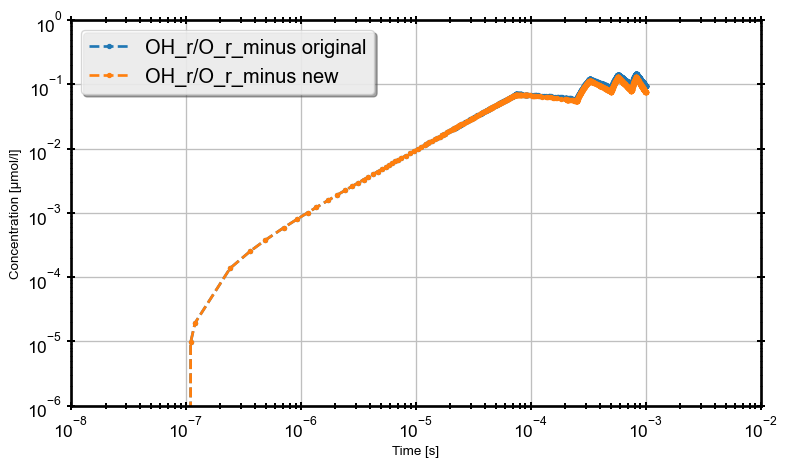

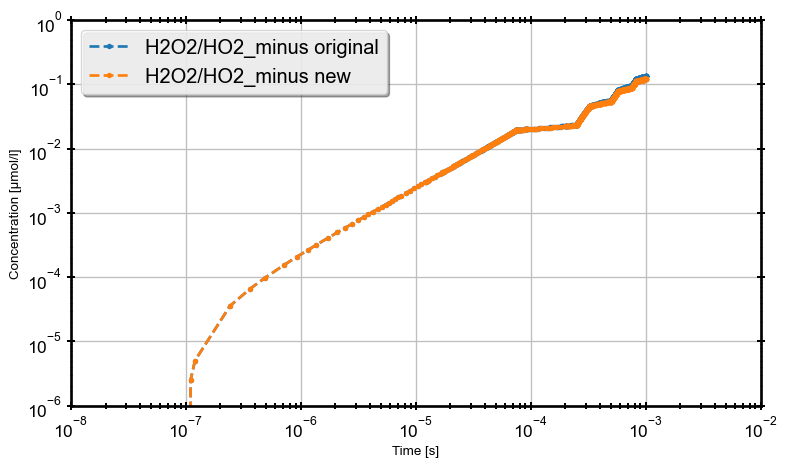

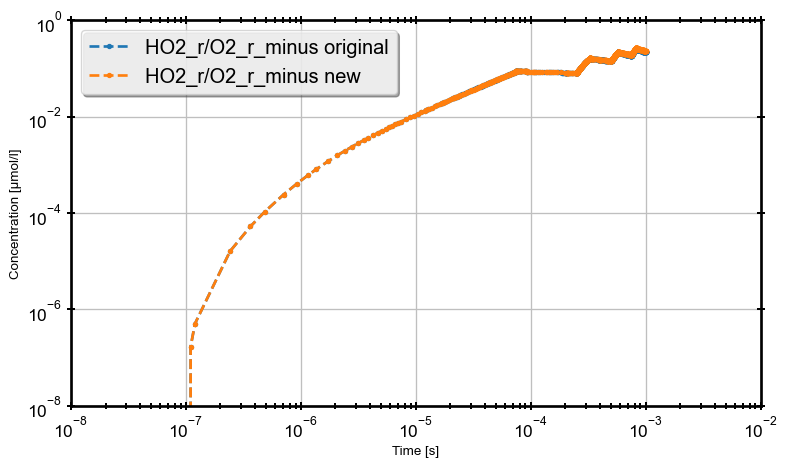

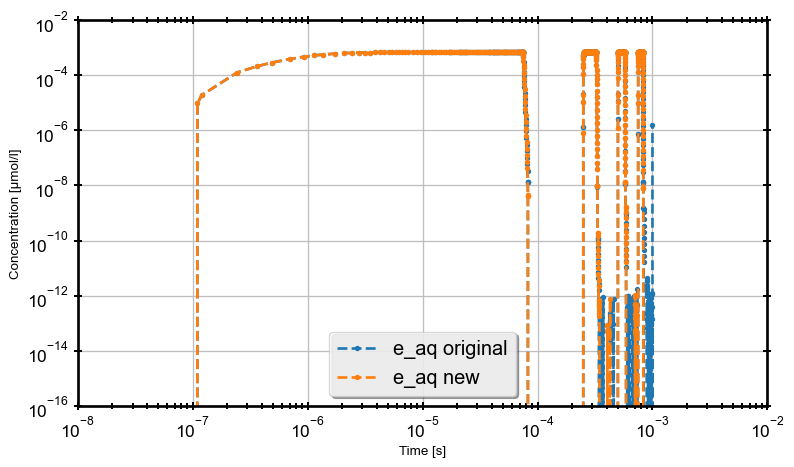

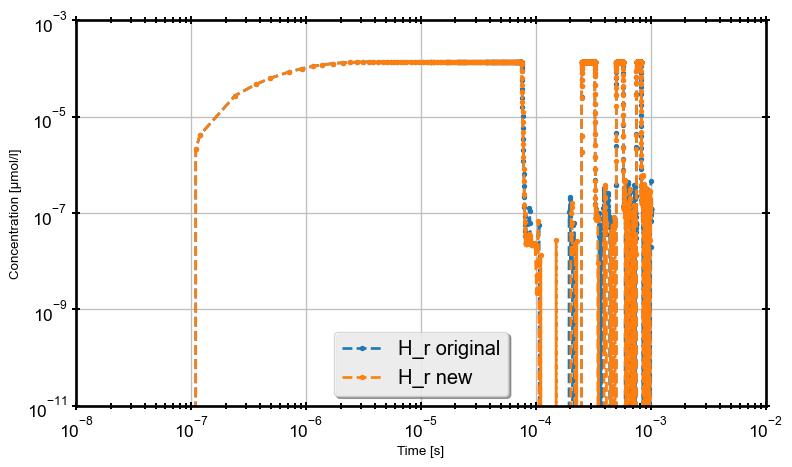

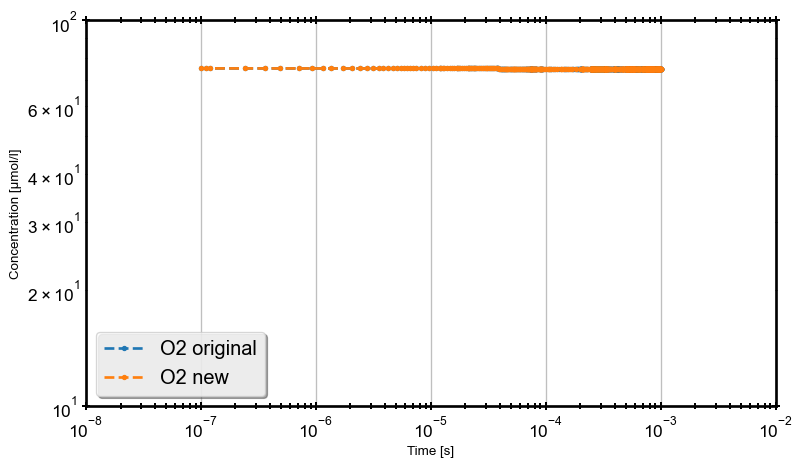

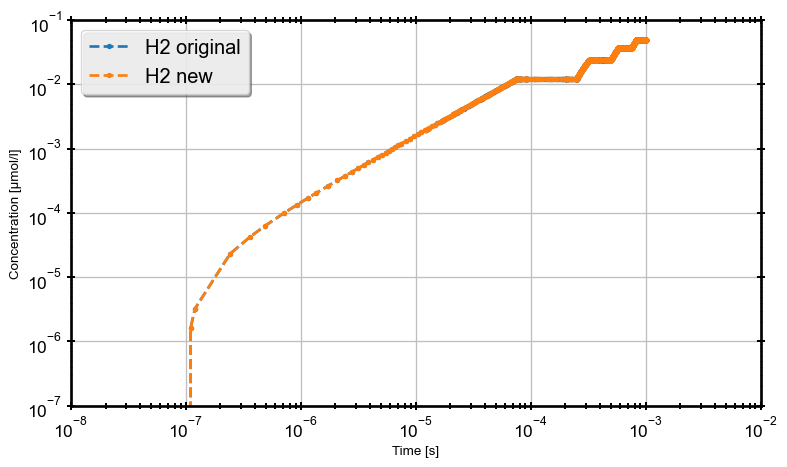

In [6]:
for (label, (sp, sp2)) in zip(env.species_labels(), zip(res.T, res2.T)):
    with fig_man.open(f"{label.replace('/', '_')} CC evolution") as (fig, ax):
        ax.loglog(time , sp , label=label + " original")
        ax.loglog(time2, sp2, label=label + " new")
        ax.legend(loc='best')
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")

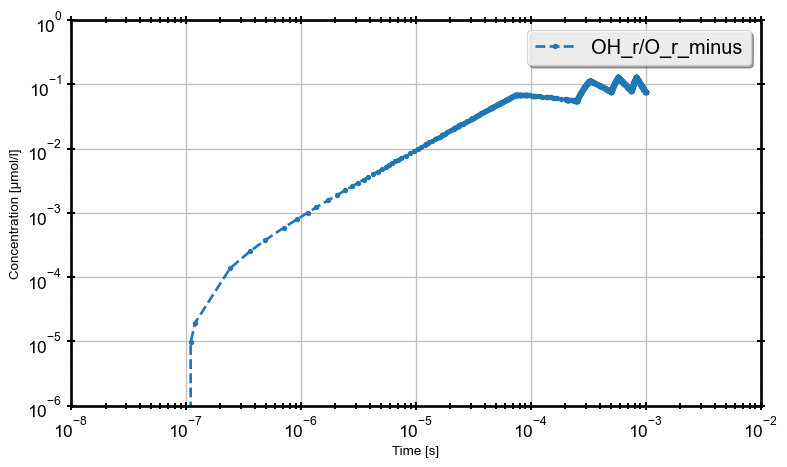

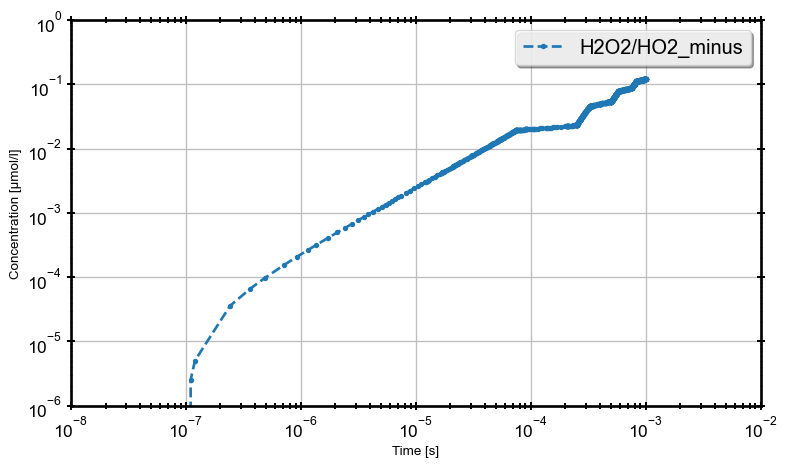

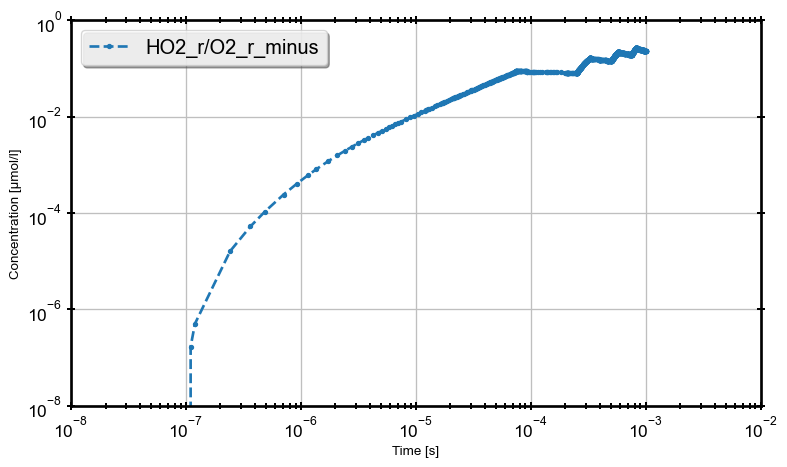

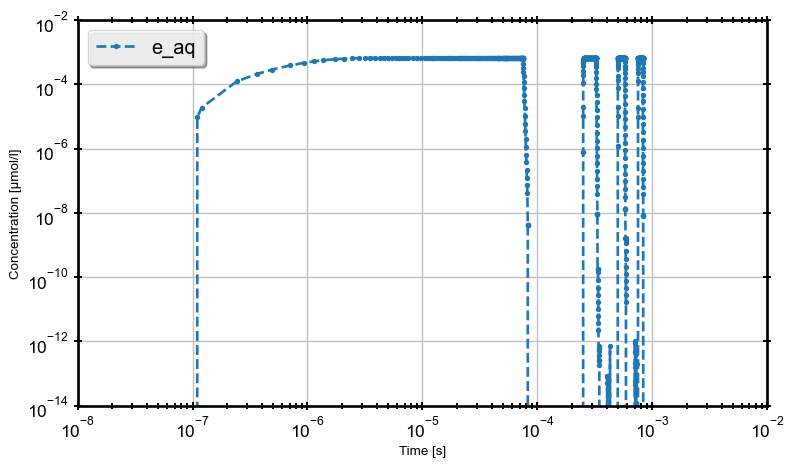

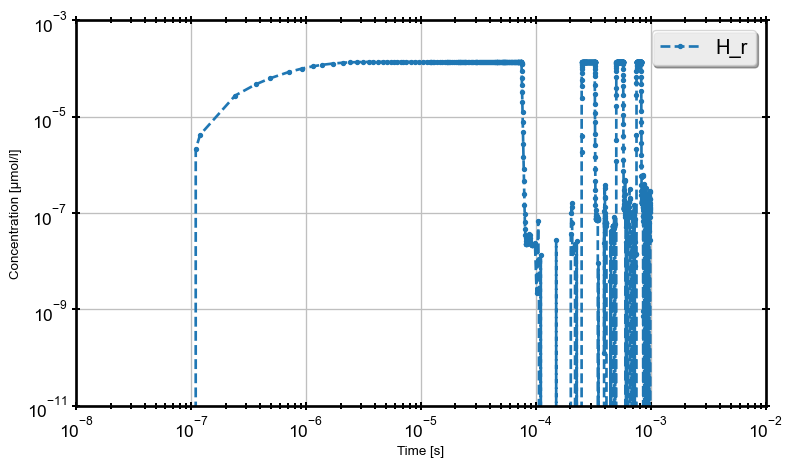

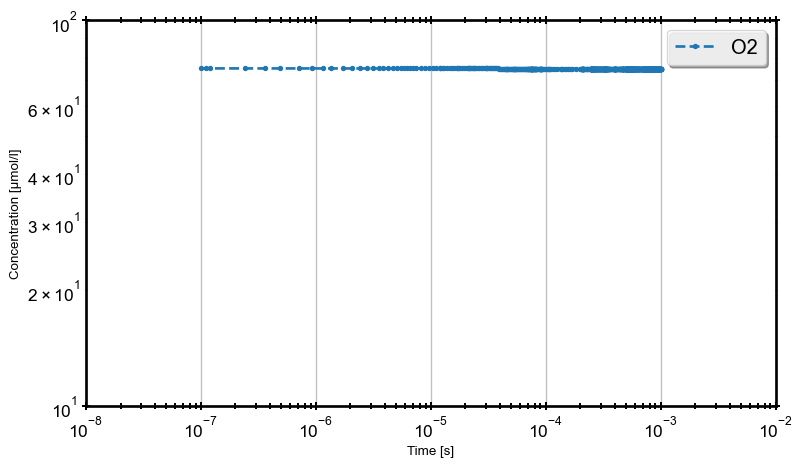

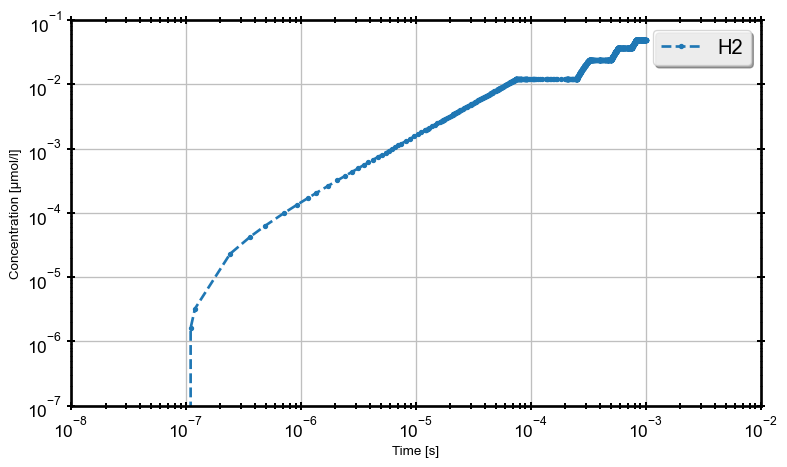

In [6]:
for label, sp2 in zip(env.species_labels(), res2.T):
    with fig_man.open(f"{label.replace('/', '_')} CC evolution") as (fig, ax):
        ax.loglog(time2, sp2, label=label)
        ax.legend(loc='best')
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")

In [8]:
for elt in env.sp_data:
    print(elt)

SnapSpecies(label='OH_r/O_r_minus', cc=0, index=0, ab_derive=1)
SnapSpecies(label='OH_r', cc=0, index=0, ab_derive=1)
SnapSpecies(label='O_r_minus', cc=0, index=0, ab_derive=1)
SnapSpecies(label='H2O2/HO2_minus', cc=0, index=1, ab_derive=1)
SnapSpecies(label='H2O2', cc=0, index=1, ab_derive=1)
SnapSpecies(label='HO2_minus', cc=0, index=1, ab_derive=1)
SnapSpecies(label='HO2_r/O2_r_minus', cc=0, index=2, ab_derive=1)
SnapSpecies(label='HO2_r', cc=0, index=2, ab_derive=1)
SnapSpecies(label='O2_r_minus', cc=0, index=2, ab_derive=1)
SnapSpecies(label='e_aq', cc=0, index=3, ab_derive=1)
SnapSpecies(label='H_r', cc=0, index=4, ab_derive=1)
SnapSpecies(label='O2', cc=0, index=5, ab_derive=1)
SnapSpecies(label='H2', cc=0, index=6, ab_derive=1)
SnapSpecies(label='H_plus', cc=0, index=None, ab_derive=1)
SnapSpecies(label='OH_minus', cc=0, index=None, ab_derive=1)
SnapSpecies(label='H2O', cc=0, index=None, ab_derive=1)


In [62]:
kwargs = {}
kwargs["max_step"] = 500e-9
kwargs["first_step"] = 10e-9
kwargs["rtol"] = 1e-6
kwargs["method"] = "LSODA" # Possibilities: ["LSODA", "BDF", "RK45"]

t_span = [1e-7, beam.time_at_max_dose*1.1]
sol = solve_ivp(derive, t_span, yinit, args= (env, beam), jac=jac, **kwargs)

kwargs["max_step"] = 1e-3
kwargs["first_step"] = None
t_span = [t_span[-1], 1]
sol2 = solve_ivp(derive, t_span, sol.y[:,-1], args= (env, beam), jac=jac, **kwargs)

res = np.vstack([sol.y.T, sol2.y.T])
time = np.vstack([sol.t[:,np.newaxis], sol2.t.T[:, np.newaxis]])

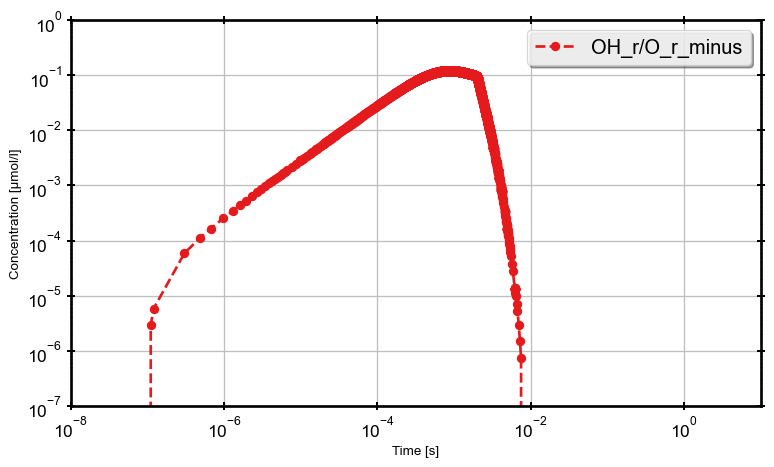

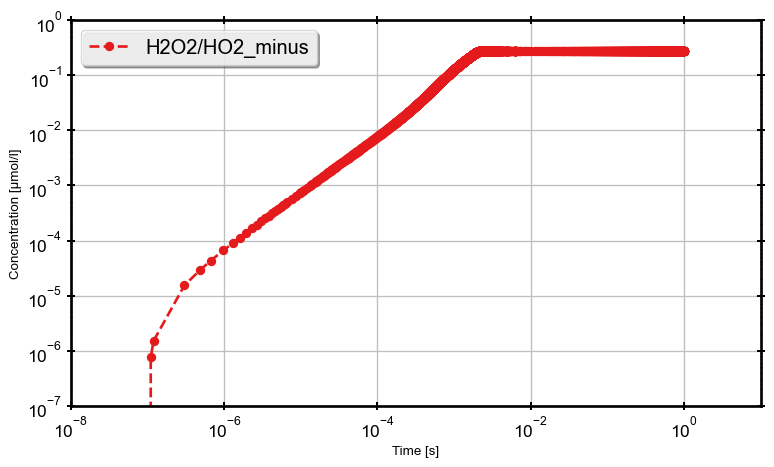

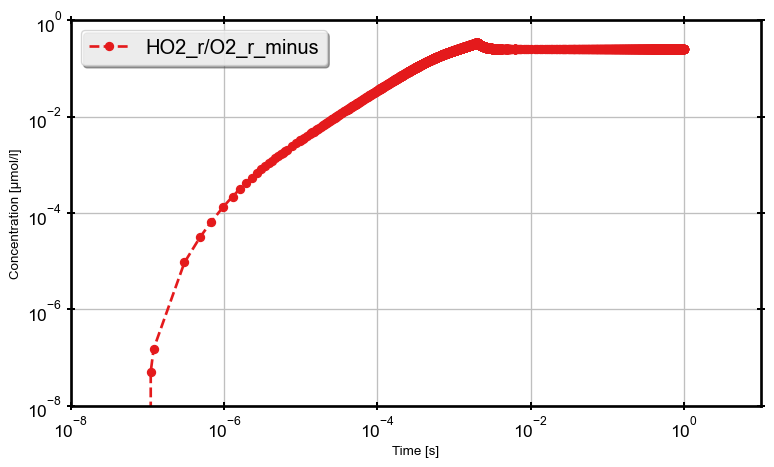

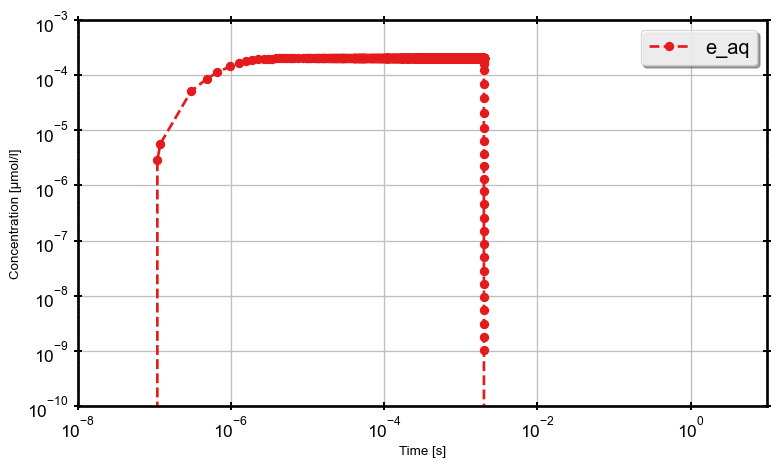

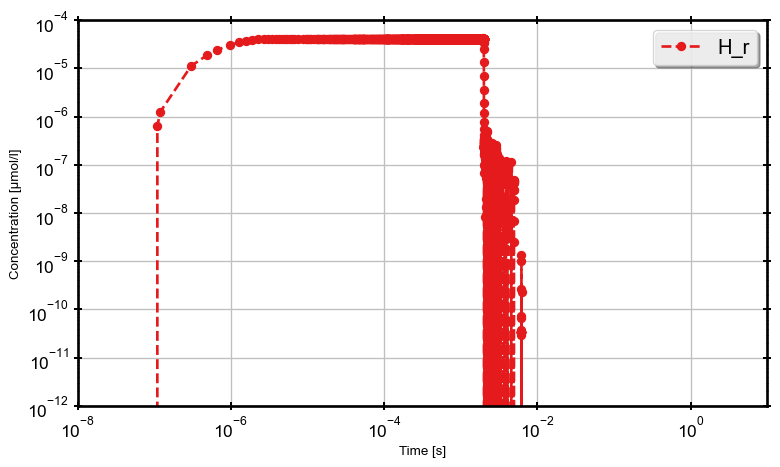

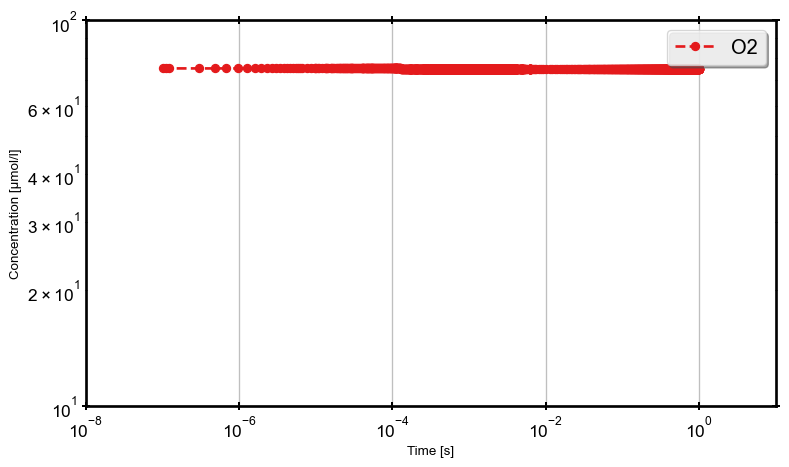

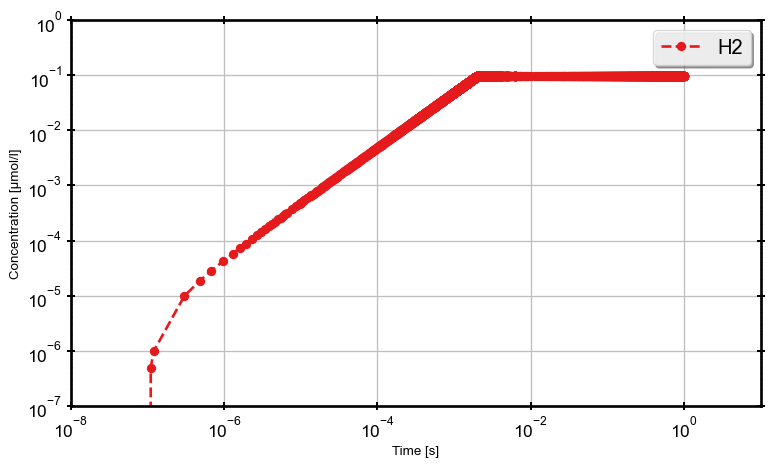

In [63]:
for label, sp in zip(env.species_labels(), res.T):
    with fig_man.open(f"{label.replace('/', '_')} CC evolution") as (fig, ax):
        ax.loglog(time, sp, label=label)
        ax.legend(loc='best')
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")

## Plot Beam shape

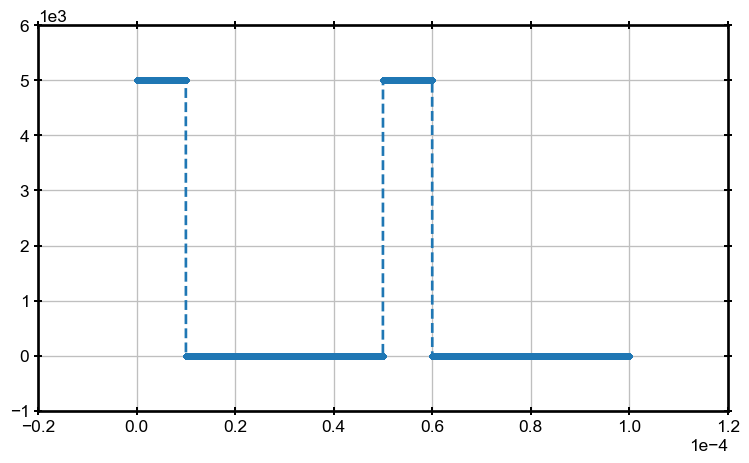

In [13]:
y_beam = np.array([beam.at(elt).dose_rate() for elt in t_sol])

with fig_man.open("Beam Shape") as (fig, ax):
    ax.plot(t_sol, y_beam)

## Recompute reaction rates based on simulation results

In [20]:
sol.y.shape

(7, 86)

In [6]:
with fig_man.open("Reaction Rates Evolution") as (fig, ax):
    for label,reaction in df:
        #ax.loglog(sol.t, sp, label=label)
        ax.plot(sol.t, , label=label)
    ax.legend(loc='best')
    ax.grid("--")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/l]")

SyntaxError: invalid syntax (2394996560.py, line 4)